# DeFi Credit Lab
### When does a higher lending rate compensate for the risk of getting stuck?

I wanted to know whether a lender could improve on Aave by ranking Morpho USDC markets on yield and adding a few observable credit screens. On the 18-month replay, Aave ended at **$10.55M** on $10M starting capital. The best Morpho rule produced **$2.63M of modeled exit cash**, or **$3.90M** if I assigned 50% recovery to the collateral-covered part of its residual claims. Aave assumes full exit at par. The comparison is a stress on what can be converted into cash under the replay's withdrawal convention.

The gap that interested me was between the balance lenders can see and the balance they can use. A borrower can owe interest for months while a lender has no immediate access to it. That makes some of the highest published yields the least informative.

In [1]:
from pathlib import Path
import gzip
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'kvr').exists())
sys.path[:0] = [str(ROOT), str(ROOT / 'src')]
from kvr import historical_replay as replay, morpho_math as mm

def read(name):
    return json.loads((ROOT / 'data' / 'processed' / name).read_text(encoding='utf-8'))

def figure(name):
    display(Image(filename=str(ROOT / 'reports' / 'figures' / name), width=760))

report = read('report_results.json')
liq = read('liq_edge.json')
saved = read('historical_replay.json')


## Data and timing

I used two samples. The liquidation study covers 886 indexed Ethereum events from 21 November 2024 to 21 November 2026 across 15 Morpho USDC markets. The borrower snapshot is tied to Ethereum block 26,465,719. The project matches market IDs to their parameters and checks share accounting, health factors and the adaptive interest-rate model against protocol state. Oracle reads for the historical profitability estimates use the execution block. A same-block update can affect that mark, so it remains an end-of-block approximation.

For the lender replay, I used daily Morpho history, positive repayment events and recorded bad debt. A market must clear the supply floor as of the lagged observation. There are 225 markets that rank at least once. This avoids selecting markets on final supply. It still depends on the indexer's historical coverage. Four archive RPC checks matched free USDC for the worked trades at their input and terminal dates. DEX quotes inform the separate stress exercise, where the available fits are snapshot observations.

## What makes a position liquidatable?

Let $C$ be collateral units, $P_o$ the oracle price in USDC, $D$ debt and $L$ the liquidation LTV. The health factor is $HF=CP_oL/D$. A borrower can be liquidatable at $HF<1$ while still having collateral worth more than its debt. Morpho's liquidation incentive determines the collateral seized for a given repayment. The liquidator's economic P&L depends on what that collateral can be sold or redeemed for:

$$\mathrm{P\&L}=Q_s P_{\mathrm{exit}}-R-G-K$$

Here $Q_s$ is seized collateral, $R$ is repayment, $G$ is gas and $K$ covers other execution and financing costs. In the toy case below, a 10% fall makes the position liquidatable while its gross collateral value remains above debt.

Price $100: HF 1.062, collateral value $10,000
Price $90: HF 0.956, collateral value $9,000


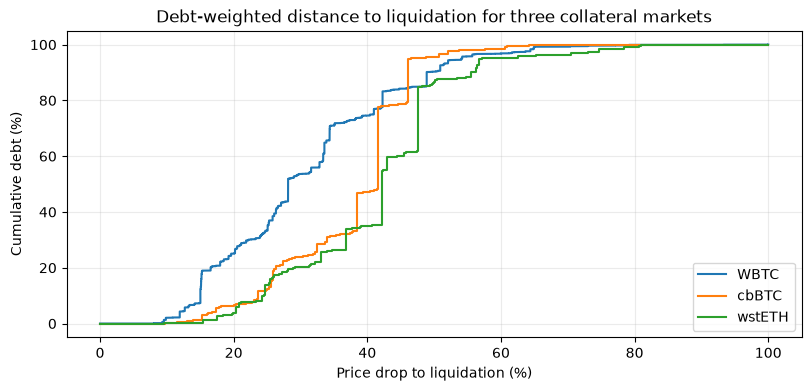

In [2]:
collateral, debt, lltv = 100, 8_000, 85 * mm.WAD // 100
for price in (100, 90):
    health = mm.max_borrow(collateral, price * mm.ORACLE_PRICE_SCALE, lltv) / debt
    print(f'Price ${price}: HF {health:.3f}, collateral value ${collateral * price:,}')
with gzip.open(ROOT / 'data/processed/demo_stress.json.gz', 'rt', encoding='utf-8') as source:
    markets = json.load(source)['markets']
fig, ax = plt.subplots(figsize=(8, 3.8), layout='constrained')
for ticker in ('WBTC', 'cbBTC', 'wstETH'):
    market = markets[f'USDC/{ticker}']
    points = []
    for p in market['positions']:
        debt = mm.borrowed(p['borrow_shares'], market['borrow_assets'], market['borrow_shares'])
        limit = mm.max_borrow(p['collateral'], market['price'], market['lltv'])
        points.append((max(0, 1 - debt / limit) if limit else 0, debt))
    drops, debts = map(pd.Series, zip(*sorted(points)))
    ax.step(100 * drops, 100 * debts.cumsum() / debts.sum(), where='post', label=ticker)
ax.set(xlabel='Price drop to liquidation (%)', ylabel='Cumulative debt (%)',
       title='Debt-weighted distance to liquidation for three collateral markets')
ax.legend(loc='lower right')
ax.grid(alpha=.25)
plt.show()

The three snapshot curves show how large collateral shocks need to be to reach the liquidation threshold. It says little about the price at which multiple liquidators could exit at once. That is why I separated the liquidation trigger from the exit-cost model.

## The historical evidence

For WBTC, cbBTC and wstETH, the modeled positive share was 97.4% to 99.6% by **priced non-dust repayment volume**. The model starts with the oracle-implied incentive and subtracts receipt gas and a 5 bp hedge charge. It assumes the oracle mark is the exit price before that charge. The estimate omits actual unwind prices, realized funding and private payments. This supports a comparison within the model. The trade records in this project cannot tell me what liquidators actually earned or whether skipped opportunities were profitable.

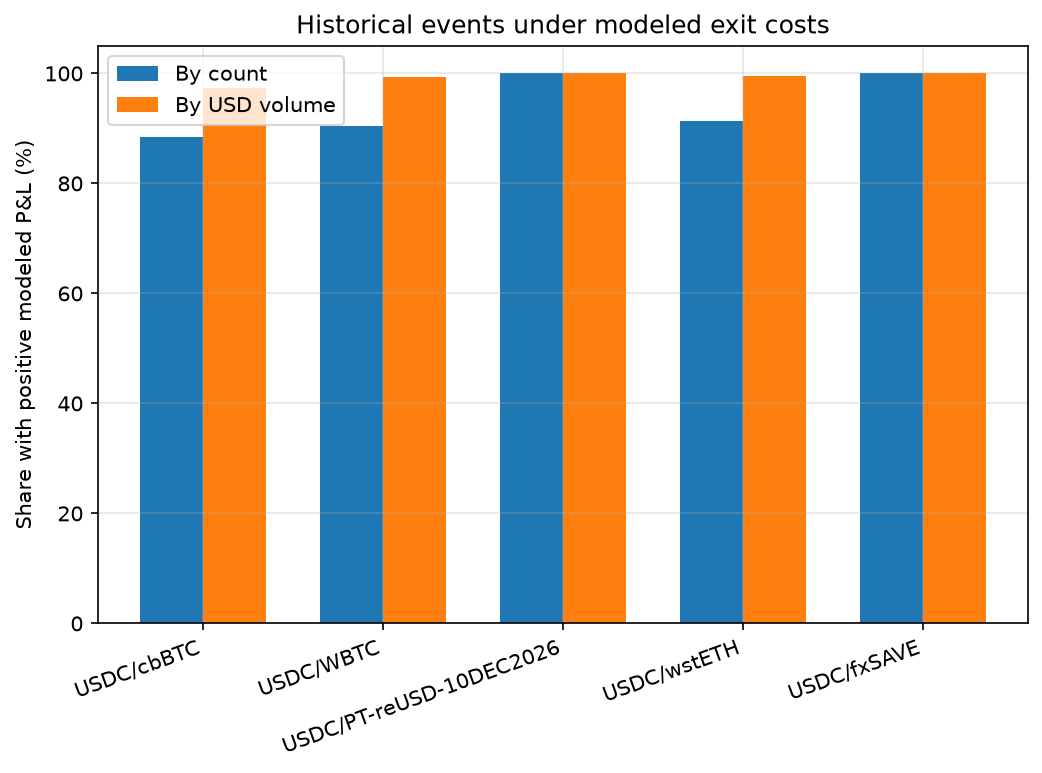

In [3]:
figure('fig7_liq_edge_profitability.png')

Weighting by volume raises the modeled share relative to weighting each event equally. The difference matters because gas consumes a larger share of a small liquidation.

The contrast is sharp for collateral with limited exit options. In one RLP position, the first recorded liquidation repaid about $777k and seized nearly 630,000 RLP. The later liquidation recorded $1.18M of bad debt after seizing the last raw collateral unit. A fixed-breakeven timing estimate could not survive a check that accounted for the intervening change in position size. I dropped that delay estimate. The two on-chain events are sufficient to establish the write-off.

2026-05-27 | repaid 776,865.782034 USDC | bad debt 0.000000 USDC
2026-06-06 | repaid 0.000002 USDC | bad debt 1,181,253.926430 USDC


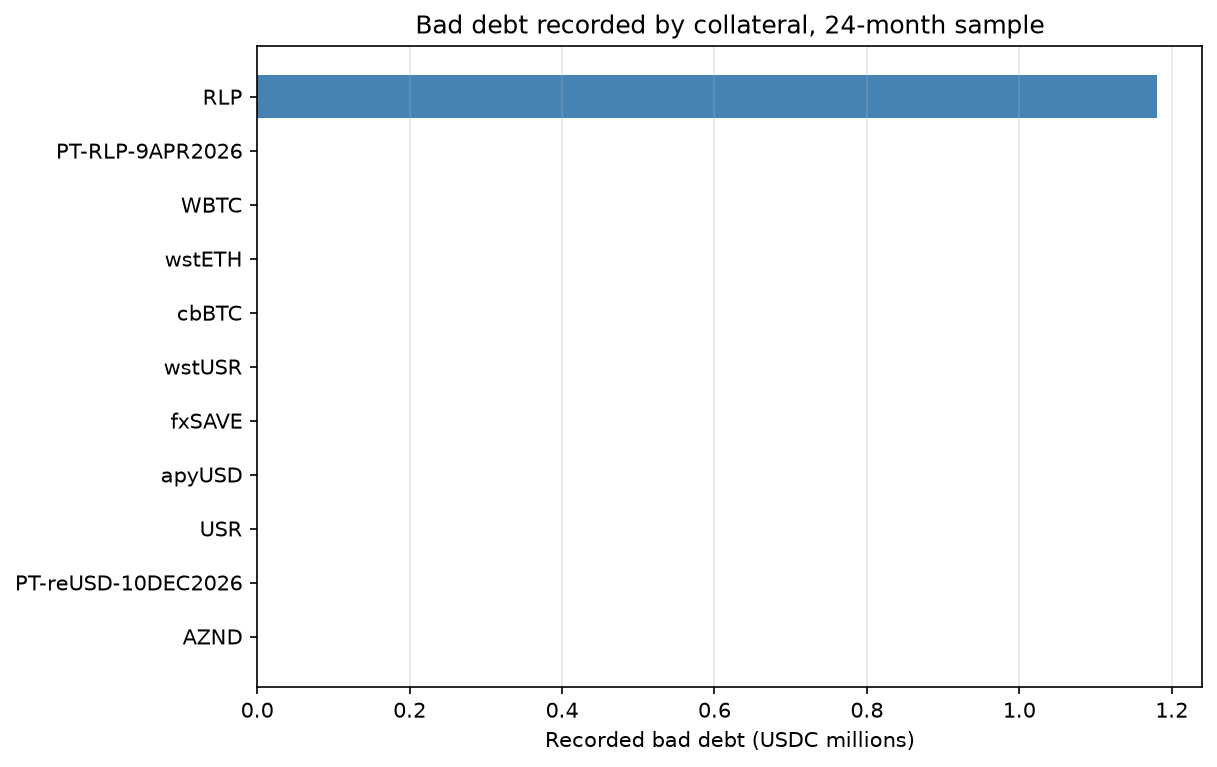

In [4]:
rlp = liq['rlp_case_study']['borrower_liquidations']
for event in rlp:
    print(f"{event['date'][:10]} | repaid {event['repaid_usdc']:,.6f} USDC | bad debt {event['bad_debt_usdc']:,.6f} USDC")
figure('fig9_liq_edge_left_on_table.png')

The recorded write-off is distinct from an unrealized collateral shortfall. The market can still have other claims that have never gone through the liquidation path.

Across the five persistently illiquid markets, accrued supply claims reached $1.22B while immediate withdrawal liquidity totaled about 161 USDC. I use the debt at the start of each observed utilization streak as historical context. Net deposits give a misleading principal estimate because withdrawals can include interest. I cannot identify the remaining lender principal from those gross flows.

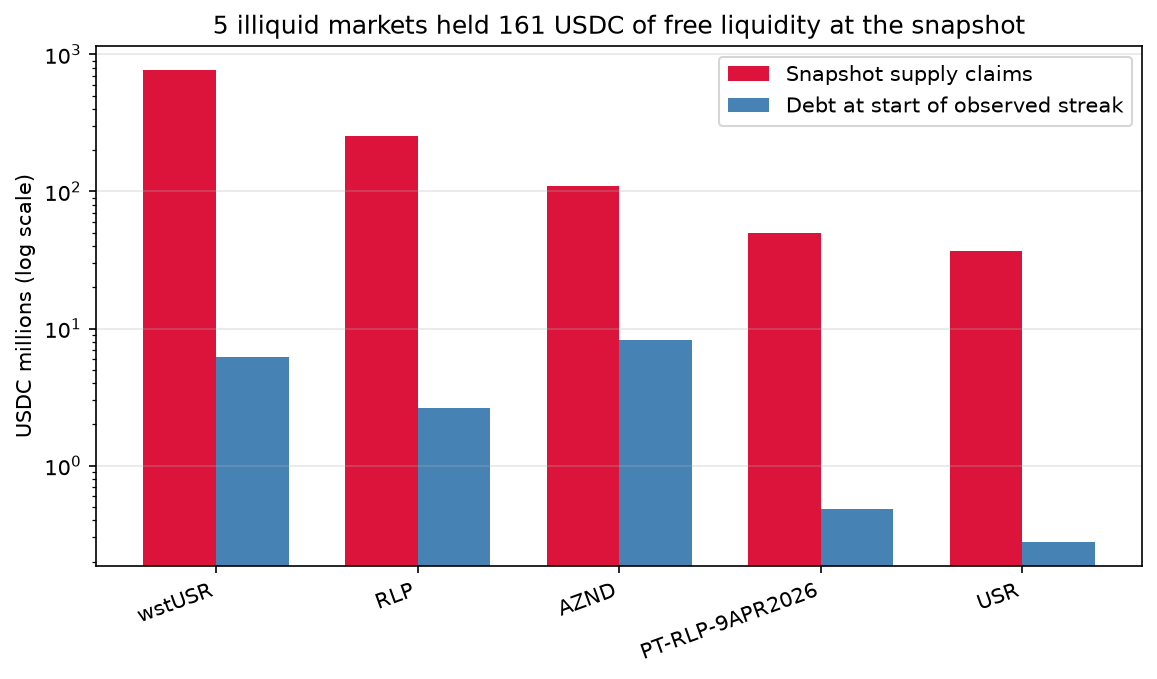

In [5]:
figure('fig10_zombie_markets.png')

The chart compares points in time. The gap includes changes in positions and accruing interest. It cannot be attributed entirely to interest. At the snapshot, near-full utilization is the direct reason other lenders cannot withdraw much from market cash.

I also modeled lending spread as expected loss, a liquidity charge and a residual. This helps organize sensitivity to the inputs. Tail frequencies are proxy estimates and the liquidity charge is assumed, so the residual is weak evidence of mispricing. The allocation optimizer is useful for studying capacity and rate dilution, with the same dependence on loss assumptions.

## Replay and portfolio implications

Starting on 22 May 2025, I ran weekly rebalances through the exit on 21 November 2026. Greedy ranks seven-day trailing rates. The first screen rejects markets with persistent near-full utilization and no recent positive repayment. The second also requires prior-day free liquidity at least equal to the initial sleeve size. I use up to five sleeves and $50 per market action. The rate model applies the lender balance times the diluted supply rate, which already includes utilization. Recorded bad debt is allocated pro rata against the opening supply base.

I model exits from observed external liquidity and hold borrow demand fixed when computing dilution. Aave pays the same $50 at entry and exit, compounds indexed base APY, and assumes full withdrawal at par. The assumptions are asymmetric. The break-even fraction below asks how much of Aave's modeled terminal value would have to be realized to tie the best Morpho rule.

,$10M exit cash,$10M at 50%,$1M at 50%
Greedy,$0,"$1,938,122","$255,049"
Repayment screen,$0,"$1,149,001","$102,169"
Liquidity screen,"$2,626,270","$3,901,690","$384,770"
Aave,"$10,554,693","$10,554,693","$1,055,377"


At 50% Morpho recovery, Aave ties at 37.0% of modeled value.


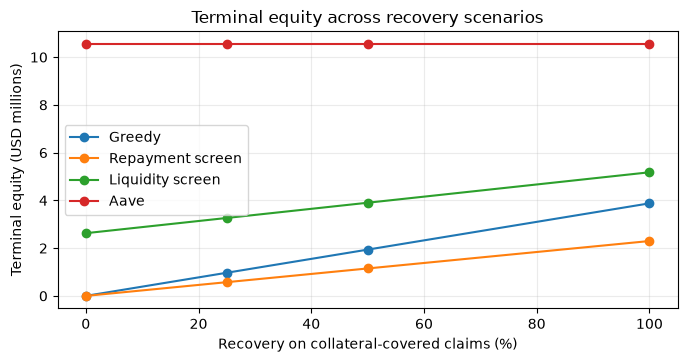

In [6]:
with gzip.open(ROOT / 'data/processed/demo_replay.json.gz', 'rt', encoding='utf-8') as f:
    inputs = json.load(f)
base = replay.run(inputs)
small = replay.run(inputs, aum=1_000_000, min_free_usdc=200_000)
assert base['table'] == saved['table']

labels = dict(zip((*replay.STRATEGIES, 'AAVE'), ('Greedy', 'Repayment screen', 'Liquidity screen', 'Aave')))
rows = {}
for key, row in base['table'].items():
    rows[labels[key]] = [row['cash_after_exit_usd'], row['equity_by_recovery_pct_usd']['50'],
                         small['table'][key]['equity_by_recovery_pct_usd']['50']]
table = pd.DataFrame.from_dict(rows, orient='index', columns=['$10M exit cash', '$10M at 50%', '$1M at 50%'])
display(table.style.format('${:,.0f}'))
break_even = replay.aave_exit_fraction_to_match_best_morpho(base['table'], 50)
assert break_even == saved['aave_exit_fraction_to_match_best_morpho']['50']
print(f'At 50% Morpho recovery, Aave ties at {break_even:.1%} of modeled value.')

fig, ax = plt.subplots(figsize=(8, 3.6))
for key, row in base['table'].items():
    ax.plot(replay.RECOVERY, [row['equity_by_recovery_pct_usd'][str(x)] / 1e6 for x in replay.RECOVERY],
            'o-', label=labels[key])
ax.set(xlabel='Recovery on collateral-covered claims (%)', ylabel='Terminal equity (USD millions)',
       title='Terminal equity across recovery scenarios')
ax.grid(alpha=.25)
ax.legend()
plt.show()

Aave led at every tested recovery rate, including at $1M in the 50% case. The repayment rule alone did poorly on marked recovery despite reducing nominal claims. In PAXG, both screens avoided a market with about 800% trailing APR and only $19.69 of free USDC. In PT-syrupUSDC, the liquidity screen skipped one market before it deteriorated, but the strategies that took it later withdrew. That distinction matters if I want to claim the screen prevented a loss.

## From credit risk research to a trading strategy

I start in Aave and reconsider the allocation weekly. For each $2M sleeve, I estimate the next week's carry using the previous seven daily observations. The Morpho rate includes the effect of my own deposit on utilization. The entry hurdle is:

$$\widehat{\Delta \mathrm{carry}}_{\mathrm{week}}=2\mathrm{M}\times 7\times(\bar r_{\mathrm{Morpho,daily}}-\bar r_{\mathrm{Aave,daily}})-4\,\mathrm{gas}.$$

I only enter at positive net carry, after checking repayment, prior-day free USDC and indexed collateral coverage. I keep eligible positions while their gross spread stays positive because entry costs are already sunk. I request an exit when a gate fails or gross spread falls to zero. Actual withdrawals can fall short. New fills are capped by opening free USDC as a conservative sizing proxy, and a partial fill must also clear the gas hurdle. Cash without a funded Morpho target goes into Aave.

All strategies start with $10M in Aave, pay the same gas per action, and use the same sleeve and execution rules where applicable. Rankings use prior-day data. Opening balances limit fills. The final 183 days are a separate evaluation window. I had already seen the broader replay, so this is a retrospective test of fixed rules. I fitted no parameters.

,Exit cash ($M),25% ($M),50% ($M),100% ($M),Drawdown (%),Turnover ($M),Mean Aave share (%)
Greedy,2.14,3.69,5.24,8.34,-47.57,116.00,46.11
Repayment screen,0.84,2.38,3.91,6.99,-60.85,92.75,24.00
Liquidity screen,8.03,8.30,8.56,9.09,-46.40,154.56,0.12
Aave,10.18,10.18,10.18,10.18,0.00,10.00,100.00
Adjusted spread,9.02,9.12,9.23,9.45,-42.66,117.35,4.75


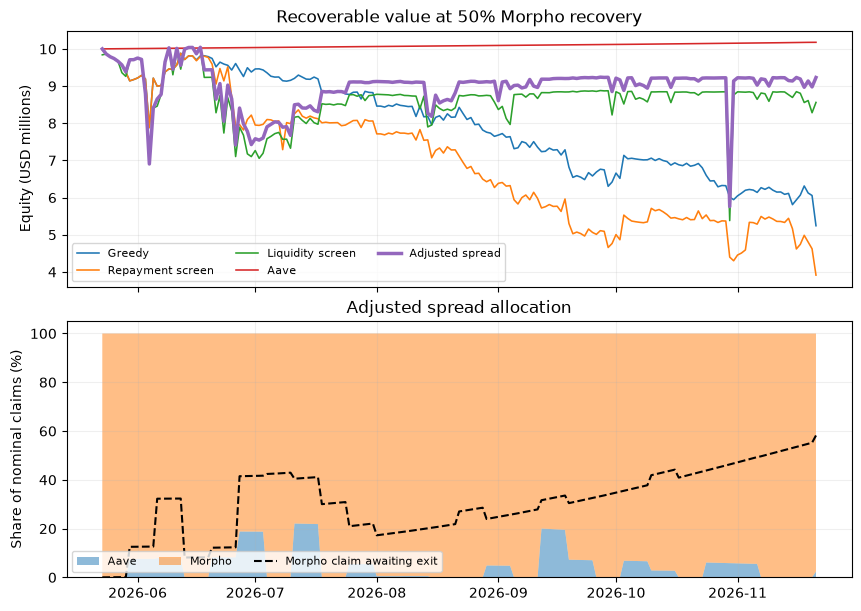

In [7]:
from kvr import spread_replay

experiment = spread_replay.run(inputs)
comparison = read('spread_replay.json')
assert experiment == comparison['base']
names = {**labels, spread_replay.SPREAD: 'Adjusted spread'}
rows = {}
for key, row in experiment['table'].items():
    equity = row['equity_by_recovery_pct_usd']
    rows[names[key]] = [
        *(equity[str(p)]/1e6 for p in (0, 25, 50, 100)),
        row['max_drawdown_at_50pct_recovery'] * 100,
        row['gross_rebalance_turnover_usd']/1e6,
        row['mean_aave_fraction'] * 100,
    ]
display(pd.DataFrame.from_dict(rows, orient='index', columns=[
    'Exit cash ($M)', '25% ($M)', '50% ($M)', '100% ($M)',
    'Drawdown (%)', 'Turnover ($M)', 'Mean Aave share (%)',
]).round(2))

fig, (ax, alloc) = plt.subplots(2, 1, figsize=(8.5, 6), sharex=True, layout='constrained')
for key, points in experiment['paths'].items():
    path = pd.DataFrame(points)
    dates = pd.to_datetime(path['date'])
    ax.plot(dates, path['marked_equity_usd']/1e6, label=names[key],
            linewidth=2.5 if key == spread_replay.SPREAD else 1.15)
    if key == spread_replay.SPREAD:
        alloc.stackplot(dates, path['aave_fraction']*100, path['morpho_fraction']*100,
                        labels=['Aave', 'Morpho'], alpha=.5)
        alloc.plot(dates, path['exit_requested_fraction']*100, color='black',
                   linestyle='--', label='Morpho claim awaiting exit')
ax.set(ylabel='Equity (USD millions)', title='Recoverable value at 50% Morpho recovery')
alloc.set(ylabel='Share of nominal claims (%)', title='Adjusted spread allocation')
for panel in (ax, alloc):
    panel.grid(alpha=.2)
    panel.legend(ncols=3, fontsize=8, loc='lower left')
plt.show()

At 50% recovery the spread rule ended at $9.23M against $8.56M for the liquidity screen and $10.18M for Aave. It spent about 4.8% of its average claim balance in Aave versus about 0.1% for the liquidity screen. It also turned over less and had a shallower recovery-mark drawdown. That suggests parking cash contributed, alongside changes in market selection and holding decisions. This replay does not isolate their individual effects.

Aave leads the spread rule at every recovery level in the base case. With a hypothetical $1M cap per Aave withdrawal, the spread rule still trails Aave at 50% recovery and edges ahead at 100% recovery, where all indexed collateral coverage is assumed recoverable and residual Aave claims are marked at par. The liquidity screen also edges ahead at 100% under that cap. A fortnightly schedule preserves a modest advantage over the liquidity screen at 50%; doubling the liquidity floor almost eliminates it. I would want historical Aave reserve liquidity, executable collateral exits and a fresh evaluation window before acting on the difference.

### Three decisions from the replay

I show the first recorded case of each action. The entry bought **msY** with a positive spread and room for the sleeve. The hold kept **reUSD** while its spread was positive. **dCOMP** fell below the liquidity floor. An exit was requested, and opening market cash funded only part of it. Later withdrawals can include repayments of balances acquired at other rebalances.

In [8]:
cases = []
for action, entry in experiment['worked_decisions'].items():
    signal = entry['signal'] or {}
    observed = entry['observed'] or {}
    cases.append({
        'Decision': action.replace('_', ' '), 'Date': entry['date'], 'Market': entry['symbol'],
        'Yield edge (%)': 100*signal['annual_yield_advantage'] if signal else None,
        'Lagged free USDC ($M)': observed.get('free_liquidity_usd', 0)/1e6,
        'Net fill ($M)': entry['trade_usdc']/1e6,
        'Later withdrawals ($M)': entry['later_withdrawals_usdc']/1e6,
        'Terminal claim ($M)': entry['terminal_residual_usdc']/1e6,
    })
display(pd.DataFrame(cases).set_index('Decision').round(2))

,Date,Market,Yield edge (%),Lagged free USDC ($M),Net fill ($M),Later withdrawals ($M),Terminal claim ($M)
Decision,,,,,,,
entry,2026-05-22,msY,5.01,2.81,2.00,2.01,11.29
blocked exit,2026-05-29,dCOMP,NaN,1.12,-0.75,4.18,0.00
hold,2026-07-10,reUSD,0.95,2.64,0.00,1.84,0.00


The ETH basis study provides a different comparison. Mean annualized carry was 5.89% at 1x and 9.45% levered. Levered carry had a lower Sharpe versus lending and required additional short margin after a rally. The trade depends on funding and on whether margin can be moved between legs when needed.

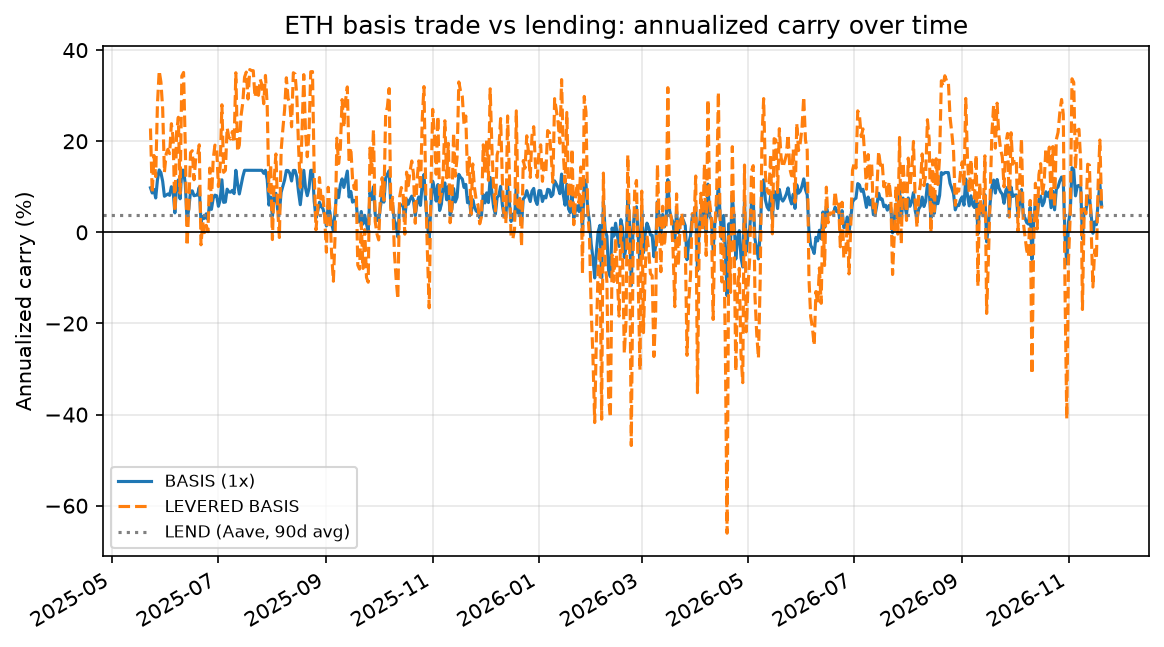

In [9]:
figure('fig12_basis_carry.png')

The basis chart is a historical carry comparison. It does not include an institutional funding or margin model.

## What I would check next

I would reconstruct the order of oracle updates, position changes and executable quotes for a small historical subset. The single power-law depth fit missed its 15% holdout tolerance, and treating simultaneous sales as one aggregate dump can overstate stress. I would also model how a new deposit changes borrow demand and how competing lenders reduce available cash. Those choices matter more than adding another ranking signal.

The Stream/xUSD case remains retrospective. The available RPCs could not validate historical Arbitrum position shares at the pre-announcement block. The later concentration is useful for describing the failed market. I leave the predictive claim open.

My conclusions are that headline lending yield is a poor ranking metric when withdrawal capacity is scarce, the free-liquidity rule improved modeled exits in this sample, and a claims balance needs a separate recovery model before it can enter an allocation decision.

**Reproduce.** Install the dependencies in `requirements-notebook.txt` and execute this notebook from the repository root. It reads the bundled data and runs the replay offline. Refreshing the data requires the endpoints and archive RPC described in the README.